Week 6 Notebook for Milestone 1

This week I'm using tree-based models on two datasets. With BRFSS, I predict frequent mental distress (14+ poor mental health days) using a single decision tree and a random forest, and compare them with the logistic regression from earlier weeks. Trees can capture interactions and non-linear patterns automatically, so this tests whether those patterns exist. I then use a random forest on the AHRQ county-level dataset to see which community factors relate to psychiatric hospitalization rates. This gives an area-level view alongside the individual-level results.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, r2_score

cols = ['MENTHLTH','PHYSHLTH','INCOME3','EMPLOY1','_HLTHPL2','MEDCOST1','GENHLTH','_AGE_G','_BMI5']
brfss = pd.read_sas('LLCP2024.XPT ', format='xport')[cols]

for c in ['MENTHLTH', 'PHYSHLTH']:
    brfss[c] = brfss[c].replace({88: 0, 77: np.nan, 99: np.nan})
brfss['INCOME3'] = brfss['INCOME3'].where(brfss['INCOME3'].between(1, 11))
brfss['GENHLTH'] = brfss['GENHLTH'].where(brfss['GENHLTH'].between(1, 5))
brfss['NO_INSURANCE'] = brfss['_HLTHPL2'].map({1: 0, 2: 1})
brfss['COST_BARRIER'] = brfss['MEDCOST1'].map({1: 1, 2: 0})
brfss['EMPLOY'] = brfss['EMPLOY1'].map({1: 'Employed', 2: 'SelfEmployed', 3: 'OutOfWork1yr+',
                                       4: 'OutOfWork<1yr', 5: 'Homemaker', 6: 'Student',
                                       7: 'Retired', 8: 'UnableToWork'})
brfss['BMI'] = brfss['_BMI5'] / 100
brfss = brfss.rename(columns={'_AGE_G': 'AGE_G'})

brfss = (brfss[['MENTHLTH','PHYSHLTH','INCOME3','GENHLTH','AGE_G','BMI',
                'NO_INSURANCE','COST_BARRIER','EMPLOY']]
         .dropna().sample(50_000, random_state=42).reset_index(drop=True))
brfss = pd.get_dummies(brfss, columns=['EMPLOY'], drop_first=True, dtype=int)

brfss['FMD'] = (brfss['MENTHLTH'] >= 14).astype(int)
X, y = brfss.drop(columns=['MENTHLTH', 'FMD']), brfss['FMD']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
print('FMD rate:', round(y.mean(), 3), '| train:', X_tr.shape, '| test:', X_te.shape)

FMD rate: 0.141 | train: (40000, 14) | test: (10000, 14)


Same 50,000-respondent BRFSS sample and frequent mental distress target as Weeks 4–5 (14.1% of respondents). Trees don’t need scaled features, so the models train on the full 40,000-row training set and are scored on the 10,000-row test set.

max_depth  train_AUC  cv_AUC
        1     0.6758  0.6752
        2     0.7317  0.7312
        3     0.7577  0.7567
        4     0.7729  0.7692
        5     0.7837  0.7749
        6     0.7927  0.7755
        7     0.8027  0.7699
        8     0.8147  0.7610
        9     0.8285  0.7495
       10     0.8454  0.7291
       11     0.8629  0.7127
       12     0.8814  0.6952
       13     0.9001  0.6766
       14     0.9177  0.6577
       15     0.9340  0.6413
     None     0.9999  0.5866

Best depth by CV AUC: 6


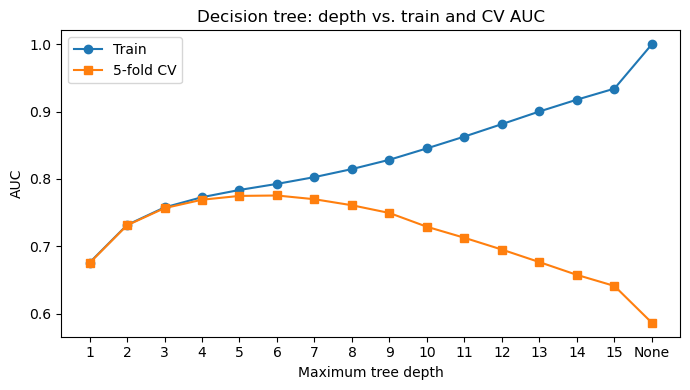

In [2]:
depths = list(range(1, 16)) + [None]
rows = []
for d in depths:
    s = cross_validate(DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42),
                       X_tr, y_tr, cv=cv, scoring='roc_auc', return_train_score=True)
    rows.append({'max_depth': 'None' if d is None else d,
                 'train_AUC': s['train_score'].mean(), 'cv_AUC': s['test_score'].mean()})
tree_curve = pd.DataFrame(rows)
print(tree_curve.round(4).to_string(index=False))

best_idx = tree_curve['cv_AUC'].idxmax()
best_depth = depths[best_idx]
print('\nBest depth by CV AUC:', best_depth)

plt.figure(figsize=(7, 4))
xs = range(len(depths))
plt.plot(xs, tree_curve['train_AUC'], 'o-', label='Train')
plt.plot(xs, tree_curve['cv_AUC'], 's-', label='5-fold CV')
plt.xticks(xs, tree_curve['max_depth'].astype(str))
plt.xlabel('Maximum tree depth'); plt.ylabel('AUC')
plt.title('Decision tree: depth vs. train and CV AUC'); plt.legend()
plt.tight_layout(); plt.show()

This is overfitting in its clearest form. As the tree gets deeper, training AUC climbs steadily to 0.9999 at unlimited depth, meaning the tree memorizes the training data. Cross-validated AUC peaks at depth 6 (0.776) and then falls, reaching 0.587 for the unlimited tree, which is barely better than guessing. Limiting depth is the main way to regularize a single tree.

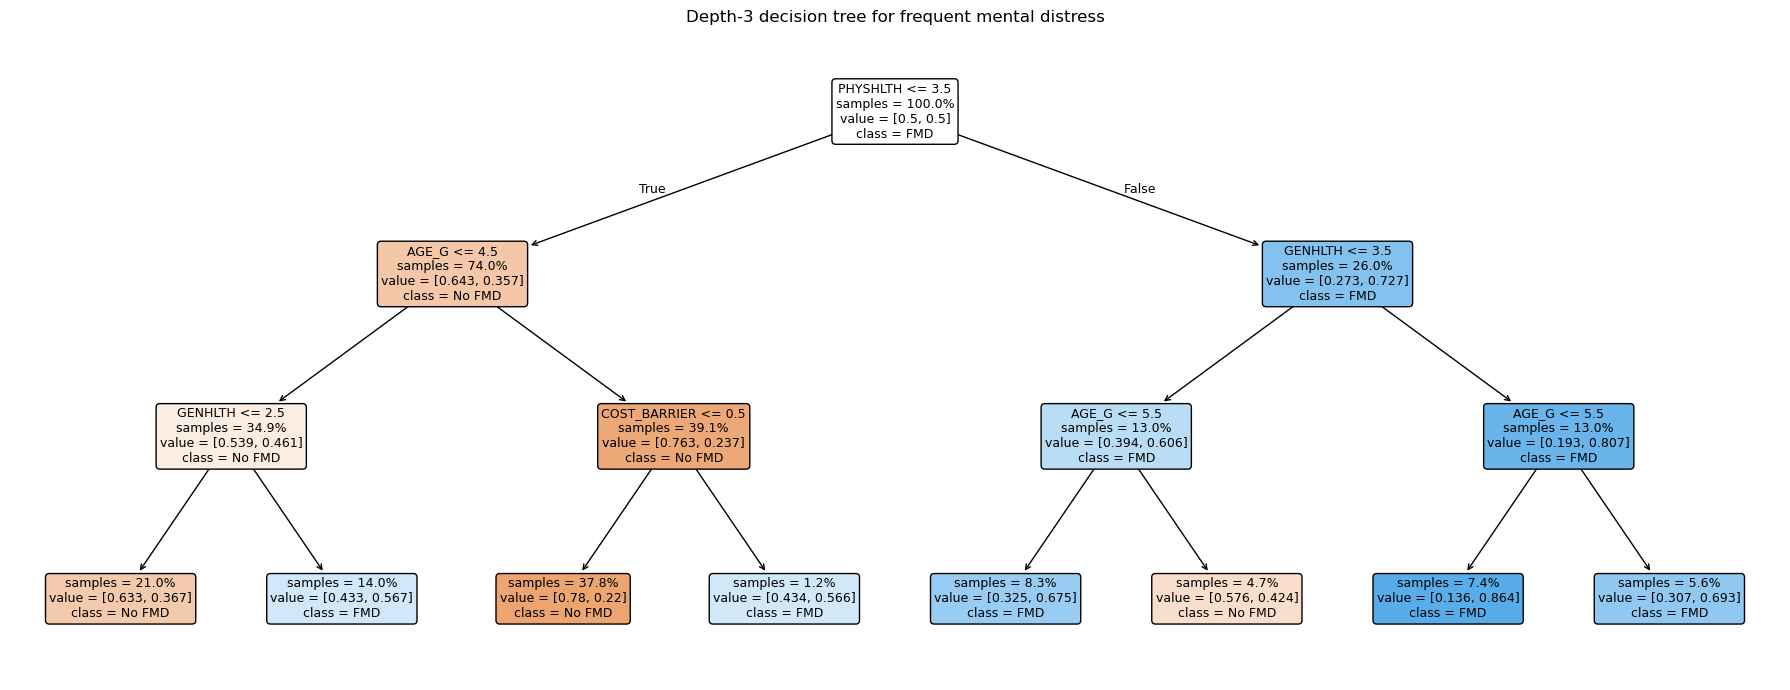

In [3]:
small = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42).fit(X_tr, y_tr)
plt.figure(figsize=(18, 7))
plot_tree(small, feature_names=X.columns, class_names=['No FMD', 'FMD'],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=9)
plt.title('Depth-3 decision tree for frequent mental distress')
plt.tight_layout(); plt.show()

This small tree is easy to read, and its splits match the earlier weeks. The first split is physical health: people with 4+ poor physical health days are much more likely to be in distress. The next splits are general health and age. The highest-risk group (86% FMD, class-weighted) is people with poor physical health, fair or poor general health, and under 65. Among people with good physical health, those under 55 who skipped care due to cost also lean toward distress. Younger people are at higher risk throughout, which matches the strong age interaction found in Week 1.

In [4]:
rf_grid = {'max_depth': [8, 12, None], 'min_samples_leaf': [1, 25, 100]}
gs = GridSearchCV(RandomForestClassifier(n_estimators=200, max_features='sqrt', class_weight='balanced',
                                         random_state=42, n_jobs=-1),
                  rf_grid, cv=StratifiedKFold(3, shuffle=True, random_state=42),
                  scoring='roc_auc', return_train_score=True)
gs.fit(X_tr, y_tr)

res = pd.DataFrame(gs.cv_results_)
show = res[['param_max_depth', 'param_min_samples_leaf', 'mean_train_score', 'mean_test_score']].copy()
show.columns = ['max_depth', 'min_samples_leaf', 'train_AUC', 'cv_AUC']
show['max_depth'] = show['max_depth'].astype(str)
print(show.sort_values('cv_AUC', ascending=False).round(4).to_string(index=False))
print('\nBest:', gs.best_params_)

max_depth  min_samples_leaf  train_AUC  cv_AUC
       12                25     0.8185  0.7936
     None                25     0.8244  0.7933
        8                25     0.8073  0.7931
       12               100     0.8028  0.7930
     None               100     0.8032  0.7930
        8               100     0.8002  0.7923
        8                 1     0.8198  0.7914
       12                 1     0.8847  0.7763
     None                 1     0.9997  0.7358

Best: {'max_depth': 12, 'min_samples_leaf': 25}


The forest’s main safeguard against overfitting is a minimum leaf size. With leaves of 1 and no depth limit, training AUC is 0.9997 but CV AUC drops to 0.736. Requiring at least 25 people per leaf closes most of that gap, and the best setting (depth 12, leaf size 25) reaches a CV AUC of 0.794. Results are nearly identical across all settings with leaves of 25 or 100.

In [5]:
rf = RandomForestClassifier(n_estimators=500, max_features='sqrt', class_weight='balanced',
                            oob_score=True, random_state=42, n_jobs=-1, **gs.best_params_)
final = {
    f'Decision tree (depth {best_depth})': DecisionTreeClassifier(max_depth=best_depth, class_weight='balanced', random_state=42),
    'Random forest (tuned, 500 trees)': rf,
    'Logistic regression (baseline)': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
}
rows = []
for name, m in final.items():
    m.fit(X_tr, y_tr)
    prob, pred = m.predict_proba(X_te)[:, 1], m.predict(X_te)
    rows.append({'model': name, 'accuracy': accuracy_score(y_te, pred),
                 'recall': recall_score(y_te, pred), 'AUC': roc_auc_score(y_te, prob)})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print('\nRandom forest out-of-bag accuracy:', round(rf.oob_score_, 3))

                           model  accuracy  recall   AUC
         Decision tree (depth 6)     0.736   0.660 0.762
Random forest (tuned, 500 trees)     0.745   0.662 0.782
  Logistic regression (baseline)     0.738   0.657 0.777

Random forest out-of-bag accuracy: 0.752


The tuned random forest is the best model so far (AUC 0.782, accuracy 74.5%, recall 0.66). It beats the single tree (0.762), because averaging 500 trees smooths out each one’s mistakes. The out-of-bag accuracy of 0.752 is close to test accuracy, which confirms the forest isn’t overfitting. Its edge over logistic regression (0.777) is small, though. Together with the Week 5 SVM results, this suggests the relationship is mostly linear, with a few interactions that trees can pick up.

                      permutation (AUC drop)  impurity
PHYSHLTH                              0.0659    0.3204
GENHLTH                               0.0341    0.2196
AGE_G                                 0.0275    0.1131
INCOME3                               0.0113    0.0811
COST_BARRIER                          0.0110    0.0877
EMPLOY_Retired                        0.0027    0.0486
EMPLOY_UnableToWork                   0.0026    0.0439
BMI                                   0.0024    0.0643
EMPLOY_OutOfWork<1yr                  0.0003    0.0045
EMPLOY_Student                        0.0003    0.0034
NO_INSURANCE                          0.0001    0.0037
EMPLOY_Homemaker                      0.0000    0.0018
EMPLOY_SelfEmployed                  -0.0000    0.0046
EMPLOY_OutOfWork1yr+                 -0.0001    0.0032


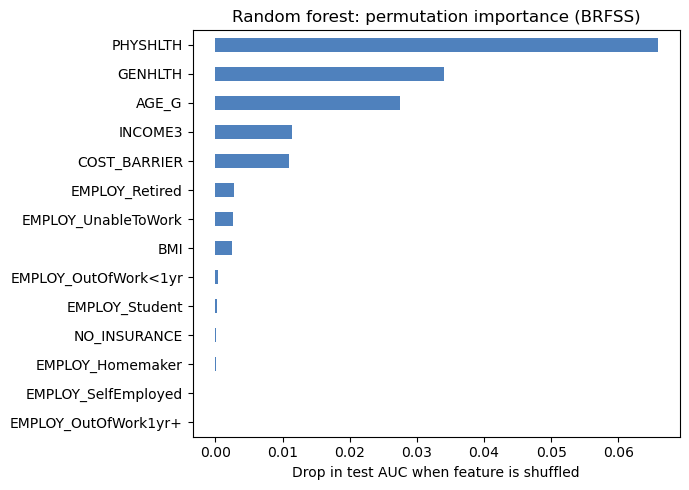

In [6]:
pi = permutation_importance(rf, X_te, y_te, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({'permutation (AUC drop)': pi.importances_mean,
                    'impurity': rf.feature_importances_}, index=X.columns)
imp = imp.sort_values('permutation (AUC drop)', ascending=False)
print(imp.round(4).to_string())

imp['permutation (AUC drop)'].sort_values().plot.barh(figsize=(7, 5), color='#4f81bd')
plt.xlabel('Drop in test AUC when feature is shuffled')
plt.title('Random forest: permutation importance (BRFSS)')
plt.tight_layout(); plt.show()

Physical health is by far the most important factor. Shuffling it lowers test AUC by 0.066, about twice as much as general health (0.034) or age (0.028). Income and cost barriers come next. Insurance status and most employment categories add almost nothing once the other factors are known. This is the same top five that forward selection picked in Week 3, so very different methods agree on what matters.

Missing columns: []
Counties: 3225
Linear regression: CV R² = 0.098 (± 0.015)
Random forest: CV R² = 0.132 (± 0.026)
Random forest test R²: 0.114


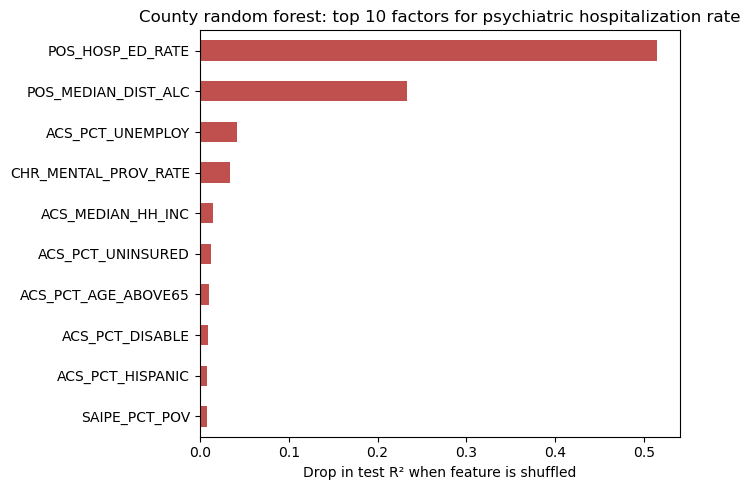

In [7]:
df6 = pd.read_csv('clh_2023_data.csv')
target = 'POS_HOSP_PSYCH_RATE'
feats = ['SAIPE_PCT_POV', 'ACS_MEDIAN_HH_INC', 'ACS_GINI_INDEX', 'ACS_PCT_UNEMPLOY', 'ACS_PCT_HH_FOOD_STMP',
         'ACS_PCT_UNINSURED', 'CHR_MENTAL_PROV_RATE', 'POS_CMHC_RATE', 'POS_FQHC_RATE', 'POS_MEDIAN_DIST_ALC',
         'POS_HOSP_ED_RATE', 'ACS_PCT_DISABLE', 'ACS_PCT_AGE_ABOVE65', 'ACS_PCT_AGE_18_29', 'ACS_PCT_BLACK',
         'ACS_PCT_HISPANIC', 'CDCW_DRUG_DTH_RATE', 'CDCW_SELFHARM_DTH_RATE']
print('Missing columns:', [c for c in feats + [target] if c not in df6.columns])
feats = [c for c in feats if c in df6.columns]

county = df6[feats + [target]].apply(pd.to_numeric, errors='coerce').dropna(subset=[target])
Xc, yc = county[feats], county[target]
print('Counties:', len(county))

cvr = KFold(5, shuffle=True, random_state=42)
lin_c = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())
rf_c  = make_pipeline(SimpleImputer(strategy='median'),
                      RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=42, n_jobs=-1))
for name, m in [('Linear regression', lin_c), ('Random forest', rf_c)]:
    s = cross_val_score(m, Xc, yc, cv=cvr, scoring='r2')
    print(f'{name}: CV R² = {s.mean():.3f} (± {s.std():.3f})')

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=42)
rf_c.fit(Xc_tr, yc_tr)
print('Random forest test R²:', round(r2_score(yc_te, rf_c.predict(Xc_te)), 3))

pic = permutation_importance(rf_c, Xc_te, yc_te, scoring='r2', n_repeats=10, random_state=42, n_jobs=-1)
imp_c = pd.Series(pic.importances_mean, index=feats).sort_values()
imp_c.tail(10).plot.barh(figsize=(7, 5), color='#c0504d')
plt.xlabel('Drop in test R² when feature is shuffled')
plt.title('County random forest: top 10 factors for psychiatric hospitalization rate')
plt.tight_layout(); plt.show()

At the county level, these community factors explain little of the variation in psychiatric hospitalization rates across 3,225 counties. The random forest reached a CV R² of 0.13 versus 0.10 for linear regression, and 0.11 on the test set. That’s lower than last semester’s ~0.24, likely because of differences in features and preprocessing. Two factors dominate. The emergency department visit rate is the biggest by far, probably because counties with hospital capacity also report more psychiatric stays, which makes it more a sign of healthcare infrastructure than of need. Median distance to substance-use facilities comes second, matching last semester’s surprise finding. Unemployment and mental health provider rates add a little. Poverty, income and insurance rates barely matter here, even though income and cost barriers mattered at the individual level. County averages blur individual differences, which supports using BRFSS as the main dataset.